*  DSC550-T302 Data Mining (2265-1)
*  2.2 Exercise: Graph Analysis with Matplotlib
*  David Jorgensen

# 2.2 Exercise: Graph Analysis with Matplotlib

In [32]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('earthquakes_1900_2026.csv')

# Print column names
print(df.columns)

# Print first few rows of the dataframe
print(df.head())

# Remove text after first space in mag_category and depth_category
df['mag_category'] = df['mag_category'].str.split(' ').str[0]
df['depth_category'] = df['depth_category'].str.split(' ').str[0]

# Set mag_category and depth_category order for better visualization
df['mag_category'] = pd.Categorical(df['mag_category'], categories=['Micro', 'Minor', 'Light', 'Moderate', 'Strong', 'Major', 'Great'], ordered=True)
df['depth_category'] = pd.Categorical(df['depth_category'], categories=['Shallow', 'Intermediate', 'Deep'], ordered=True)

# Create decade column for time-based analysis
df['decade'] = (df['year'] // 10) * 10

# Print first few rows of the wrangled dataframe
print(df.head())

Index(['id', 'time', 'year', 'month', 'day_of_year', 'hour', 'latitude',
       'longitude', 'depth', 'mag', 'magType', 'place', 'type', 'tsunami',
       'mag_category', 'depth_category', 'nst', 'gap', 'dmin', 'rms', 'net',
       'updated', 'status'],
      dtype='object')
                      id                       time  year  month  day_of_year  \
0  cent19000105190000000  1900-01-05 19:00:00+00:00  1900      1            5   
1  cent19000111090700000  1900-01-11 09:07:00+00:00  1900      1           11   
2  cent19000120063300000  1900-01-20 06:33:00+00:00  1900      1           20   
3  cent19000131192200000  1900-01-31 19:22:00+00:00  1900      1           31   
4               ushis388  1900-04-09 14:00:00+00:00  1900      4           99   

   hour  latitude  longitude  depth  mag  ... tsunami mag_category  \
0    19     -3.00     102.00    NaN  7.0  ...       0  Major (6-7)   
1     9     -5.00     148.00    NaN  7.0  ...       0  Major (6-7)   
2     6     20.00    -105.0

# Instructions

1. Using a data set of your choice, write an introduction explaining the data set.
2. Identify a question or question(s) that you would like to explore in your data set.
3. Create at least three graphs that help answer these questions. Make sure your graphs are clearly readable and are labeled appropriately and professionally.
4. Explain what you have learned from each of your graphs.
5. Write a conclusion that summarizes your findings.

# Assignment

## Dataset Summary

DATASET: Earthquakes 1900-2026
Retrieved from Kaggle, [darkmatternet/global-earthquake-history-1m-since-1900](https://www.kaggle.com/datasets/darkmatternet/global-earthquake-history-1m-since-1900).

This dataset contains every earthquake recorded by the USGS since 1900 that exceeded a magnitude of 2.5.

Columns:
- id: Unique USGS event identifier
- time: UTC timestamp
- year, month, day_of_year, hour: Extracted time components
- latitude, longitude: Epicenter coordinates
- depth: Depth in km
- mag: Magnitude
- magType: Magnitude type (ml, mb, mw, etc.)
- place: Human-readable location description
- type: Event type (earthquake, explosion, etc.)
- tsunami: 1 if the event generated a tsunami warning, 0 otherwise
- mag_category: Minor / Light / Moderate / Strong / Major / Great / Massive
- depth_category: Shallow (0-70km) / Intermediate (70-300km) / Deep (300-700km)
- nst: Number of seismic stations used
- gap: Largest azimuthal gap between stations (degrees)
- dmin: Distance to nearest station (degrees)
- rms: Root mean square travel time residual (seconds)
- net: Contributing network ID
- status: reviewed or automatic

Key stats:
- 1,054,000+ earthquakes
- Date range: 1900 to present
- 120+ M8+ events (including the 1960 Chile M9.5 and 2011 Japan M9.1)
- 1,100+ M7+ events
- Global coverage with clear Ring of Fire, Mid-Atlantic Ridge, and Alpide Belt patterns

## Analysis

1. Is there a correlation between earthquake magnitude and epicenter depth?
2. Do strong earthquakes cluster together around specific times or are they spread out uniformally over history? 

### Is there a correlation between earthquake magnitude and epicenter depth?

To explore this, I'll need columns `depth`, `mag`, `mag_category`, and `depth_category`.

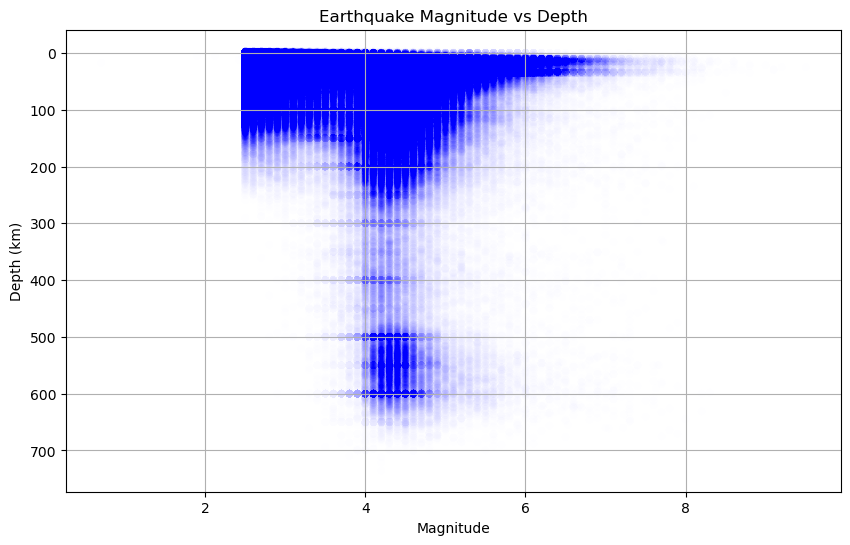

In [40]:
# Chart 1: Scatter plot of magnitude vs depth
plt.figure(figsize=(10, 6))
plt.scatter(df['mag'], df['depth'], alpha=0.005, color='blue', edgecolors='none') # Set alpha to 0.005 to make points more transparent and reduce overplotting
plt.title('Earthquake Magnitude vs Depth')
plt.xlabel('Magnitude')
plt.ylabel('Depth (km)')
plt.gca().invert_yaxis() # Invert y-axis to have depth increasing downwards
plt.grid()
plt.show()

It seems like most earthquakes occur within 150 km of the surface, but magnitude 4-5 concentrates between 0-250 km and 500-600 km. The problem with this chart is it shows the depth and magnitude of most earthquakes, but doesn't help identify correlations between depth and magnitude for less common distributions. 

<Figure size 1000x600 with 0 Axes>

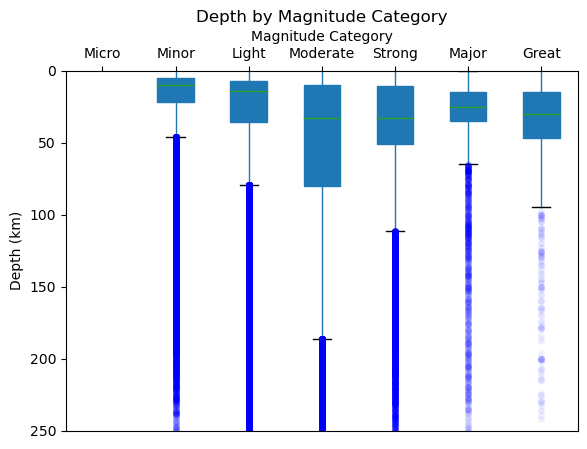

In [41]:
# Chart 2: Box plot of depth by mag_category
plt.figure(figsize=(10, 6))
df.boxplot(column='depth', by='mag_category', flierprops=dict(marker='o', markerfacecolor='blue', markersize=5, alpha=0.05, linestyle='none', markeredgewidth=0), patch_artist=True) # Set flierprops to make outliers less visible
plt.title('Depth by Magnitude Category')
plt.suptitle('')  # Remove default title to avoid overlap
plt.xlabel('Magnitude Category')
plt.ylabel('Depth (km)')
plt.gca().xaxis.tick_top()
plt.gca().xaxis.set_label_position('top')
plt.gca().invert_yaxis() # Invert y-axis to have depth increasing downwards
plt.ylim(250, 0) # Set y-axis limits to focus on depth range of interest
plt.grid()
plt.show()

A box plot should help mitigate the first chart's shortcoming. Here we see again that most earthquakes occur 0-50 km depth. Moderate, which represents earthquakes of magnitude 4-5, again shows a right-skew thanks to the strong clustering around 500-600 km. Strong (mag 5-6) and Great (mag 7-8) also have right-skews, although less prominent than Moderate. Major (mag 6-7) stands out as clustering within a very narrow band between 15-30 km in depth, a much more concentrated range than the other upper cateogories.

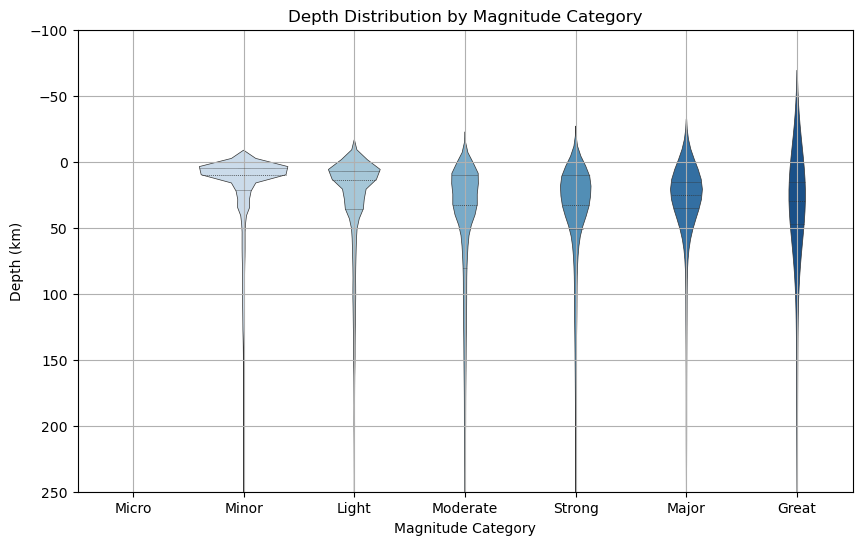

In [42]:
# Chart 3: Violin plot of depth by magnitude category using seaborn
plt.figure(figsize=(10, 6))
sns.violinplot(x='mag_category', y='depth', data=df, linewidth=0.5, inner='quartile', palette='Blues') # Set linewidth to 0.5 to make violins less thick, inner to 'quartile' to show quartiles, and palette to 'Blues' for a blue color scheme
plt.title('Depth Distribution by Magnitude Category')
plt.xlabel('Magnitude Category')
plt.ylabel('Depth (km)')
plt.gca().invert_yaxis() # Invert y-axis to have depth increasing downwards
plt.ylim(250, -100) # Set y-axis limits to focus on depth range of interest
plt.grid()
plt.show()

We see here similar distributions as in the box plots, but now we have a better understanding of volume. The density plot shows that the vast majority of earthquakes occur at shallow depths, with a smaller but still significant number occurring at intermediate depths. Deep earthquakes are much less common. This suggests that while most earthquakes occur near the surface, there are certain depth ranges where specific magnitude categories are more likely to occur.

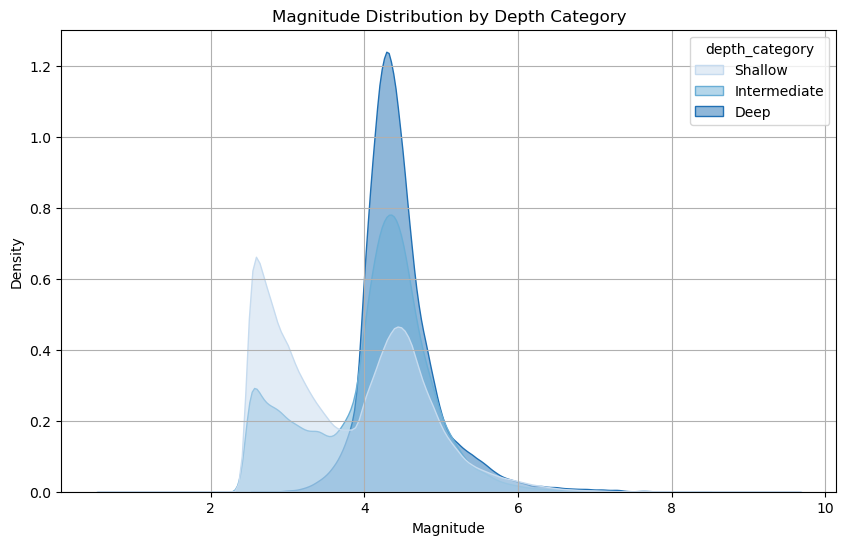

In [7]:
# Chart 4: Density plot of depth_category vs mag
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='mag', hue='depth_category', fill=True, common_norm=False, palette='Blues', alpha=0.5) # Set fill to True to fill the area under the curves, common_norm to False to normalize each category separately, palette to 'Blues' for a blue color scheme, and alpha to 0.5 to make curves more transparent
plt.title('Magnitude Distribution by Depth Category')
plt.xlabel('Magnitude')
plt.ylabel('Density')
plt.grid()
plt.show()

Now let's look at the distribution of earthquake magnitudes across different depth categories. We see that shallow earthquakes have a wider range of magnitudes, with strong density peaks at 2.5-3 and 4-5 magnitudes. Intermediate earthquakes tend to cluster around moderate magnitudes (4-5) but also have a broader distribution, a minor spike also at 2.5-3 magnitude. Deep earthquakes are almost exclusively between 4-5 magnitude. This suggests that while shallow earthquakes can range from minor to strong, deeper earthquakes are more likely to be moderate in magnitude.

**Conclusion:** Overall, there is a clear correlation between earthquake magnitude and depth. Shallow earthquakes exhibit a wide range of magnitudes, including the strongest events, while deeper earthquakes tend to be more moderate in magnitude. My guess is that this pattern likely reflects the geological processes at play, with shallow earthquakes occurring in more varied tectonic settings and deeper earthquakes being influenced by specific subduction zone dynamics.

## Do strong earthquakes cluster together around specific times or are they spread out uniformally over history?

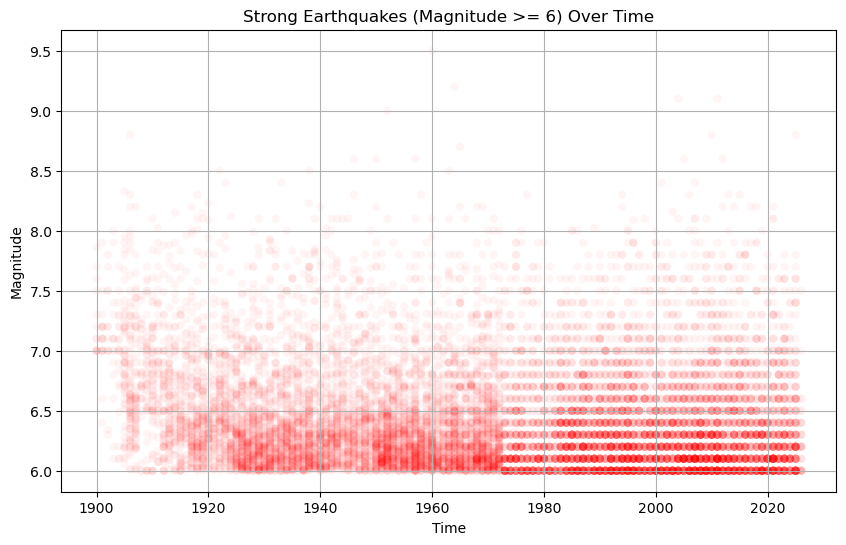

In [36]:
# Chart 1: Time series of strong earthquakes (magnitude >= 6) over time
plt.figure(figsize=(10, 6))
strong_earthquakes = df[df['mag'] >= 6]
plt.scatter(strong_earthquakes['year'], strong_earthquakes['mag'], alpha=0.04, color='red', edgecolors='none') # Set alpha to 0.5 to make points more transparent and reduce overplotting
plt.title('Strong Earthquakes (Magnitude >= 6) Over Time')
plt.xlabel('Time')
plt.ylabel('Magnitude')
plt.grid()
plt.show()

Hmm, not so helpful. Upon first glance it looks like strong earthquakes are fairly uniformly distributed over time, but the sheer volume of points makes it difficult to identify any meaningful patterns. However, the data does show an interesting change in how magnitude was measured starting around 1970, with densities snapping to .1 magnitude intervals. This is likely due to the introduction of the moment magnitude scale (Mw) which provides more precise measurements, especially for larger earthquakes.

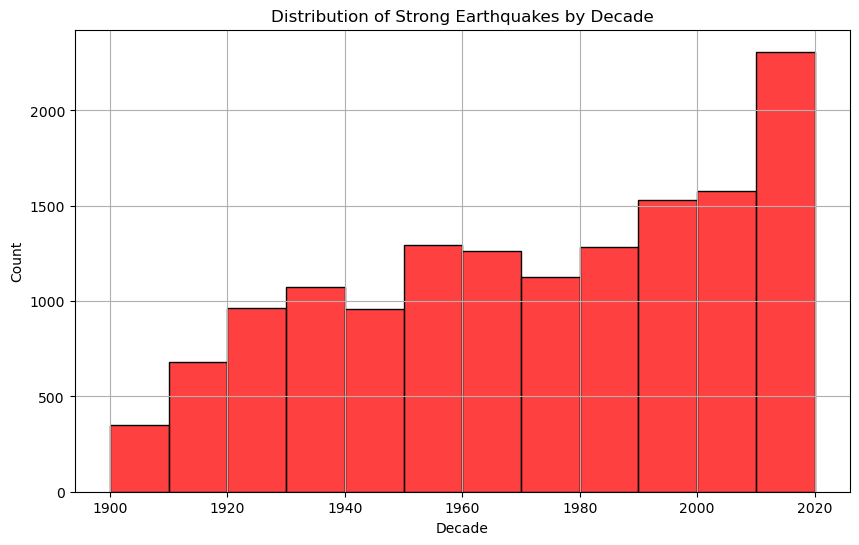

In [37]:
# Chart 2: Histogram of strong earthquakes by decade
plt.figure(figsize=(10, 6))
sns.histplot(strong_earthquakes['decade'], bins=range(1900, 2030, 10), color='red', edgecolor='black') # Set bins to cover each decade, color to red, and edgecolor to black for better visibility
plt.title('Distribution of Strong Earthquakes by Decade')
plt.xlabel('Decade')
plt.ylabel('Count')
plt.grid()
plt.show()

This histogram shows that the number of measured strong earthquakes (magnitude >= 6) has increased since 1900, with a large peak in the 2010s. This could be due to a combination of factors, including improved detection technology, increased seismic activity, and better reporting. However, it's important to note that the increase in recorded strong earthquakes may not necessarily reflect an actual increase in earthquake frequency, but rather an improvement in our ability to detect and measure them.

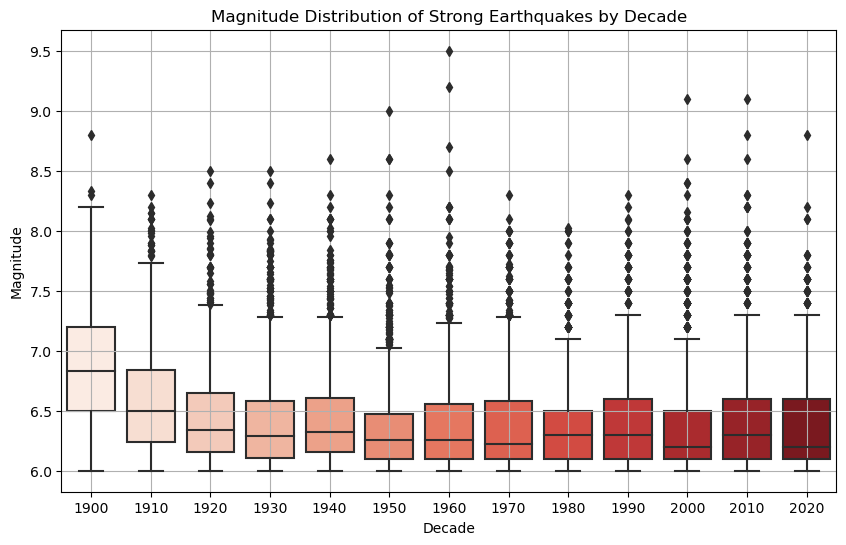

In [38]:
# Chart 3: Box plot of magnitude by decade for strong earthquakes
plt.figure(figsize=(10, 6))
sns.boxplot(x='decade', y='mag', data=strong_earthquakes, palette='Reds') # Set palette to 'Reds' for a red color scheme
plt.title('Magnitude Distribution of Strong Earthquakes by Decade')
plt.xlabel('Decade')
plt.ylabel('Magnitude')
plt.grid()
plt.show()

The box plot shows that the median magnitude of strong earthquakes has remained relatively stable over time, with some minorfluctuations. However, there is a noticeable decrease in the (IQR) in early decades, which could be due to underreporting of smaller strong earthquakes in the early 20th century. The 2010s show a wider range of magnitudes, which may reflect improved detection capabilities and a more comprehensive recording of strong earthquakes in recent years.

**Conclusion**: Overall, while strong earthquakes appear to be somewhat uniformly distributed over time, there are indications of increased detection and reporting in recent decades. The median magnitude of strong earthquakes has remained relatively stable, but the range of recorded magnitudes has expanded, likely due to advancements in seismic monitoring technology.